# Is the mechanistic latency model functioning?

**Model under test.** A team's latency is predicted as the sum, over its static
instructions, of the CV32E40X manual's cycle cost for each:

$$\widehat{L} = \sum_{\text{op}} \text{cost}(\text{op}) \times \text{count}(\text{op})$$

`cost` comes from `analysis/disassembler.py` (`INSTRUCTION_LATENCY`), transcribed
from the OpenHW CV32E40X user manual, *Pipeline Details* -> "Cycle Counts Per
Instruction Type". Because the manual's hazard penalties are **pairwise** effects
that are deliberately excluded from that table, this sum is a *stall-free floor*:
it should always be **below** the measurement. That gives a falsifiable property
to test, not just a goodness-of-fit number.

**What this notebook establishes**, each with the calculation attached:

| # | Claim | Section |
|---|-------|---------|
| 1 | How a team is classified straight-line vs branchy | 1 |
| 2 | On straight-line teams the model works (R2 ~ 0.98, floor holds) | 3 |
| 3 | On branchy teams it breaks, and the floor violation says *why* | 4 |
| 4 | An instrumentation overcost provably exists — measured, not assumed | 5 |
| 5 | A systematic scale factor sits on top of the doc floor | 6 |
| 6 | What the per-instruction costs actually are, fitted vs doc | 7 |

In [73]:
# --- Configuration -----------------------------------------------------------
DB_PATH = "db_fixedpt_iset32_inline"
UARCH   = "cv32e40x_im1_zba_zbb"

import sys, os
from collections import Counter
from dataclasses import dataclass, field

import numpy as np
import matplotlib.pyplot as plt

# Find the project root (the directory holding classes/) by walking up, so the
# notebook works whatever directory the kernel was started in.
ROOT = os.path.abspath(os.getcwd())
while not os.path.isdir(os.path.join(ROOT, "classes")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
os.chdir(ROOT)                      # so DB_PATH resolves relative to the repo

from classes.database import Database
from analysis.disassembler import Disassembler, INSTRUCTION_LATENCY
from analysis.analyzer import FeaturesAnalyzer

db = Database.load(DB_PATH)
print(f"{len(db.tpgs)} TPGs | uarchs: {list(db.uarchs)} | ISAs: {list(db.isas)}")

[Database] Loaded from db_fixedpt_iset32_inline  (161 TPGs, 2 ISAs, 2 uarchs)
161 TPGs | uarchs: ['cv32e40x_im1_zba_zbb', 'cv32e40x_im2_zba_zbb'] | ISAs: ['rv32im_zicsr_zba_zbb', 'rv32i_zicsr_zmmul_zba_zbb']


In [74]:
# --- Plot style + palette ----------------------------------------------------
# Categorical slots 1-3 of the validated default palette. Scatter plots use the
# all-pairs pairlist, where only the first three slots clear the CVD floors, so
# the analysis never needs a 4th colour: every chart here is at most
# straight-line vs branchy, plus a neutral reference line.
C_STRAIGHT = "#2a78d6"   # slot 1, blue
C_BRANCHY  = "#eb6834"   # slot 2, orange
C_THIRD    = "#1baf7a"   # slot 3, aqua
INK        = "#3d3d3a"
MUTED      = "#8a8a80"

plt.rcParams.update({
    "figure.figsize": (7.5, 4.6), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlecolor": INK,
    "axes.grid": True, "grid.color": "#e6e6e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlesize": 11, "axes.titlelocation": "left", "axes.titleweight": "semibold",
    "font.size": 9, "legend.frameon": False,
})

@dataclass
class Fit:
    '''An ordinary least-squares fit, with the numbers that matter printed.'''
    beta: np.ndarray; names: list; r2: float; mae: float
    pred: np.ndarray; cond: float; n: int

    def __repr__(self):
        terms = "  ".join(f"{nm}={b:+.3f}" for nm, b in zip(self.names, self.beta[:-1]))
        warn = "   [!] collinear, read coefficients with care" if self.cond > 30 else ""
        return (f"n={self.n}  {terms}  const={self.beta[-1]:+.2f}"
                f"   R2={self.r2:.4f}  MAE={self.mae:.2f} cyc{warn}")

def ols(X, y, names=None):
    '''Least squares of y on the columns of X plus an intercept.'''
    X = np.asarray(X, float)
    if X.ndim == 1: X = X[:, None]
    y = np.asarray(y, float)
    A = np.hstack([X, np.ones((len(y), 1))])
    beta, *_ = np.linalg.lstsq(A, y, rcond=None)
    pred = A @ beta
    r2 = 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    names = names or [f"x{i}" for i in range(X.shape[1])]
    return Fit(beta, names, r2, float(np.abs(y - pred).mean()), pred,
               float(np.linalg.cond(A)), len(y))
print("helpers ready")

helpers ready


## 1. How a team is classified: straight-line vs branchy

This is the split everything downstream rests on, so it is made explicit here.

A **CompiledTeam is "branchy" if its disassembly contains at least one control-flow
instruction**, and "straight-line" otherwise. Control flow is the set below: the six
RV32I conditional branches, their pseudo-instruction forms as objdump prints them
(`bltz`, `beqz`, ...), and the unconditional jumps (`j`, `jal`, `jalr`, `ret`).

The distinction matters because of *static vs dynamic* counting. The model sums
every instruction **present in the code**. That equals what the processor
**executes** only when control flows straight through. As soon as a branch exists,
some instructions are skipped on any given run, while the measurement —
`AvgCyclesPerTeam` — records only the path actually taken.

The next cell lists every mnemonic in the database with its table cost and
classification, so nothing about the split is hidden.

In [75]:
CONTROL_FLOW = {
    # RV32I conditional branches
    "beq", "bne", "blt", "bge", "bltu", "bgeu",
    # branch pseudo-instructions objdump prints instead of the above
    "beqz", "bnez", "blez", "bgez", "bltz", "bgtz", "bgt", "ble", "bgtu", "bleu",
    # unconditional jumps (incl. pseudo forms)
    "jal", "jalr", "j", "jr", "ret", "call", "tail",
}

ops_seen = Counter()
for _tpg, _tid, ct in db.all_compiled_teams():
    for i in (ct.instructions or []):
        ops_seen[i.operation] += 1

print(f"{'operation':<26}{'cost':>6}{'count':>10}   class")
print("-" * 60)
for op, cnt in ops_seen.most_common():
    mnem = op.lower().split("_")[0]
    kind = "CONTROL FLOW" if mnem in CONTROL_FLOW else ""
    print(f"{op:<26}{Disassembler.operation_latency(op):>6}{cnt:>10}   {kind}")

operation                   cost     count   class
------------------------------------------------------------
add                            1     38538   
mul                            1     27854   
lw                             1     23828   
sw                             1     17665   
srai                           1     16900   
slli                           1     15752   
srli                           1     13817   
lui                            1     13736   
mulhu                          4     10417   
addi                           1      9467   
sub                            1      7462   
mv                             1      5857   
li                             1      4408   
max                            1      4155   
bltz                           1      2143   CONTROL FLOW
blt                            1      1828   CONTROL FLOW
sh1add                         1      1674   
div                           35      1481   
neg                            1    

In [76]:
def is_branchy(instructions):
    '''True if the team contains any control-flow instruction.'''
    return any(i.mnemonic.lower() in CONTROL_FLOW for i in instructions)

LOADS  = {"lw", "lh", "lb", "lhu", "lbu"}
STORES = {"sw", "sh", "sb"}
MULH   = {"mulh", "mulhu", "mulhsu"}

@dataclass
class TeamRow:
    tpg: str; team_id: int; ops: Counter; n: int
    meas: float; stddev: float; nruns: int
    branchy: bool; load_use: int; alu_haz: int

rows = []
for tpg, tid, ct, m in db.get_measurements_for_uarch(UARCH):
    ins = ct.instructions or []
    if not ins:
        continue                      # 2 teams have no parsed instructions
    # Distance-1 RAW hazards, split by whether the producer was a load: the
    # manual charges +1 for a load-use hazard and nothing for an ALU-ALU one.
    h = FeaturesAnalyzer._raw_hazard_counts(ins, max_distance=1)
    lu = sum(v for (_d, p, _c), v in h.items() if p.split("_")[0] in LOADS)
    rows.append(TeamRow(
        tpg=tpg.name, team_id=tid, ops=Counter(i.operation for i in ins), n=len(ins),
        meas=m.latency, stddev=m.stddev, nruns=m.nb_measurements,
        branchy=is_branchy(ins), load_use=lu, alu_haz=sum(h.values()) - lu,
    ))

SL = np.array([not r.branchy for r in rows])
meas = np.array([r.meas for r in rows], float)
nins = np.array([r.n for r in rows], float)
lu   = np.array([r.load_use for r in rows], float)

print(f"{len(rows)} measured teams with instructions")
print(f"  straight-line : {SL.sum():>5}   mean measured = {meas[SL].mean():6.1f} cycles")
print(f"  branchy       : {(~SL).sum():>5}   mean measured = {meas[~SL].mean():6.1f} cycles")
cv = np.array([r.stddev / r.meas * 100 if r.meas else 0 for r in rows])
print(f"\nMeasurement noise: median CV = {np.median(cv):.2f}%, p90 = {np.percentile(cv, 90):.2f}%"
      f", median runs/team = {np.median([r.nruns for r in rows]):.0f}")
print("-> the measurements are essentially deterministic; nothing below is noise.")

3275 measured teams with instructions
  straight-line :  2028   mean measured =   30.4 cycles
  branchy       :  1247   mean measured =  130.0 cycles

Measurement noise: median CV = 0.00%, p90 = 2.20%, median runs/team = 10
-> the measurements are essentially deterministic; nothing below is noise.


## 2. The estimator, made tunable

`estimate()` takes a cost table so the doc's run-time-dependent rows can be varied
without touching the module. `COSTS` starts as the manual's table; override any
entry and re-run the sections below to iterate.

In [77]:
COSTS = dict(INSTRUCTION_LATENCY)   # edit freely, e.g. COSTS["div"] = 3

def estimate(row, costs=None):
    '''Sum(cost(op) x count(op)) for one team.'''
    costs = costs or COSTS
    total = 0.0
    for op, cnt in row.ops.items():
        op = op.lower()
        if op in costs:
            total += costs[op] * cnt
        else:                                  # "jal_<callee>": jump only
            total += costs.get(op.split("_")[0], 1) * cnt
    return total

est = np.array([estimate(r) for r in rows], float)
print(f"estimate: mean={est.mean():.1f}  median={np.median(est):.0f}  max={est.max():.0f} cycles")

estimate: mean=86.8  median=22  max=963 cycles


## 3. Straight-line teams

Here static count == dynamic count, so the model's core assumption holds. Two
things are checked: the fit, and the **floor property** (estimate <= measured),
which is the falsifiable part.

In [78]:
def report(mask, label):
    e, y = est[mask], meas[mask]
    f = ols(e, y, ["estimate"])
    viol = (e > y)
    print(f"{label}  ({mask.sum()} teams)")
    print(f"  fit            : measured = {f.beta[0]:.3f} x estimate {f.beta[1]:+.1f}"
          f"   R2 = {f.r2:.4f}   MAE = {f.mae:.2f} cycles")
    print(f"  floor violated : {viol.sum()}/{mask.sum()} = {100*viol.mean():.1f}%"
          f"   (estimate > measured, impossible for a stall-free floor)")
    print(f"  measured       : mean={y.mean():.1f}  median={np.median(y):.0f} cycles")
    return f

fit_sl = report(SL, "STRAIGHT-LINE")

STRAIGHT-LINE  (2028 teams)
  fit            : measured = 1.123 x estimate +8.4   R2 = 0.9775   MAE = 2.05 cycles
  floor violated : 5/2028 = 0.2%   (estimate > measured, impossible for a stall-free floor)
  measured       : mean=30.4  median=26 cycles


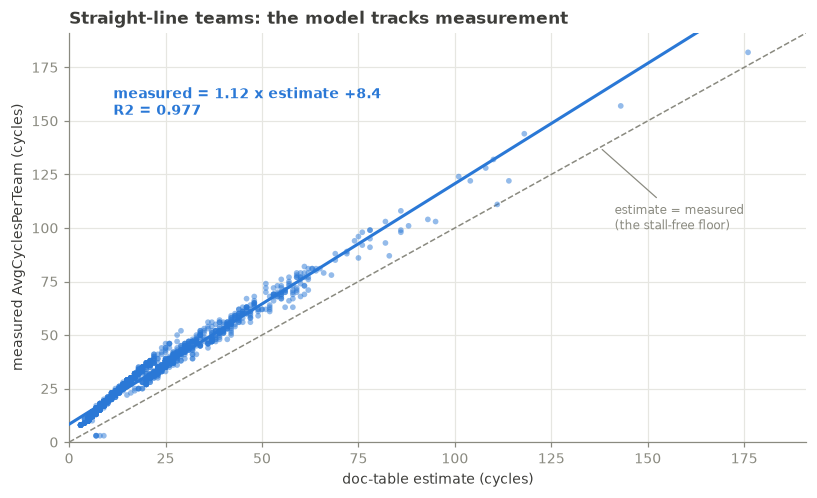

In [79]:
fig, ax = plt.subplots()
e, y = est[SL], meas[SL]
lim = max(e.max(), y.max()) * 1.05
ax.plot([0, lim], [0, lim], color=MUTED, lw=1, ls="--", zorder=1)
ax.annotate("estimate = measured\n(the stall-free floor)", xy=(lim*0.72, lim*0.72),
            xytext=(lim*0.74, lim*0.52), color=MUTED, fontsize=8,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
ax.scatter(e, y, s=14, color=C_STRAIGHT, alpha=0.5, edgecolor="none", zorder=2)
xs = np.linspace(0, lim, 2)
ax.plot(xs, fit_sl.beta[0]*xs + fit_sl.beta[1], color=C_STRAIGHT, lw=2, zorder=3)
ax.annotate(f"measured = {fit_sl.beta[0]:.2f} x estimate {fit_sl.beta[1]:+.1f}\nR2 = {fit_sl.r2:.3f}",
            xy=(lim*0.30, fit_sl.beta[0]*lim*0.30 + fit_sl.beta[1]), xytext=(lim*0.06, lim*0.80),
            color=C_STRAIGHT, fontsize=9, fontweight="semibold")
ax.set(xlabel="doc-table estimate (cycles)", ylabel="measured AvgCyclesPerTeam (cycles)",
       xlim=(0, lim), ylim=(0, lim),
       title="Straight-line teams: the model tracks measurement")
plt.tight_layout(); plt.show()

**Reading it.** Points sit above the dashed identity line: the estimate is a floor,
as designed. The fitted slope is the systematic gap quantified in section 6.

## 4. Branchy teams

Same estimator, same uarch, same measurement method. The only change is that these
teams contain control flow.

In [80]:
fit_br = report(~SL, "BRANCHY")
print()
fit_all = report(np.ones(len(rows), bool), "ALL TEAMS POOLED")

BRANCHY  (1247 teams)
  fit            : measured = 0.559 x estimate +20.3   R2 = 0.5403   MAE = 59.56 cycles
  floor violated : 647/1247 = 51.9%   (estimate > measured, impossible for a stall-free floor)
  measured       : mean=130.0  median=76 cycles

ALL TEAMS POOLED  (3275 teams)
  fit            : measured = 0.565 x estimate +19.2   R2 = 0.6561   MAE = 27.04 cycles
  floor violated : 652/3275 = 19.9%   (estimate > measured, impossible for a stall-free floor)
  measured       : mean=68.3  median=33 cycles


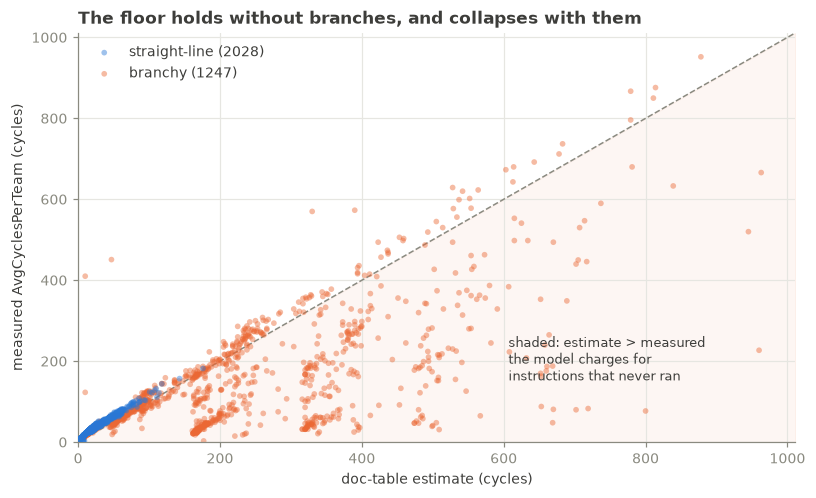

In [81]:
fig, ax = plt.subplots()
lim = max(est.max(), meas.max()) * 1.05
ax.plot([0, lim], [0, lim], color=MUTED, lw=1, ls="--", zorder=1)
ax.scatter(est[SL],  meas[SL],  s=14, color=C_STRAIGHT, alpha=0.45,
           edgecolor="none", label=f"straight-line ({SL.sum()})", zorder=3)
ax.scatter(est[~SL], meas[~SL], s=14, color=C_BRANCHY, alpha=0.45,
           edgecolor="none", label=f"branchy ({(~SL).sum()})", zorder=2)
ax.fill_between([0, lim], [0, 0], [0, lim], color=C_BRANCHY, alpha=0.06, zorder=0)
ax.annotate("shaded: estimate > measured\nthe model charges for\ninstructions that never ran",
            xy=(lim*0.60, lim*0.14), color=INK, fontsize=8.5, ha="left", va="bottom")
ax.set(xlabel="doc-table estimate (cycles)", ylabel="measured AvgCyclesPerTeam (cycles)",
       xlim=(0, lim), ylim=(0, lim),
       title="The floor holds without branches, and collapses with them")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

In [82]:
# Floor violation as a function of how much control flow a team has.
nbr = np.array([sum(c for op, c in r.ops.items()
                    if op.lower().split("_")[0] in CONTROL_FLOW) for r in rows], float)
viol = est > meas
bins = [0, 1, 2, 3, 5, 9, 17, 1000]
print(f"{'branches in team':<20}{'teams':>8}{'floor violated':>16}{'median est/meas':>18}")
print("-" * 62)
for lo, hi in zip(bins[:-1], bins[1:]):
    m = (nbr >= lo) & (nbr < hi)
    if m.sum() == 0: continue
    lbl = f"{lo}" if hi == lo + 1 else f"{lo}-{hi-1}" if hi < 1000 else f"{lo}+"
    print(f"{lbl:<20}{m.sum():>8}{100*viol[m].mean():>15.1f}%"
          f"{np.median(est[m]/np.maximum(meas[m],1e-9)):>18.2f}")

branches in team       teams  floor violated   median est/meas
--------------------------------------------------------------
0                       2028            0.2%              0.54
1                        412           21.1%              0.69
2                        128           21.9%              0.78
3-4                       73           30.1%              0.93
5-8                      326           73.3%              1.61
9-16                     257           87.5%              1.86
17+                       51           90.2%              1.97


**The diagnosis is the violation rate, not the R2.** An estimate *exceeding* the
measurement has exactly two possible causes:

1. the sum includes instructions the processor never executed, or
2. some instruction is priced **too high** in the table.

A missing stall, an uncounted callee body or probe overhead cannot do it — those all
make the *measurement* larger, never the estimate. But cause 2 is a live suspect
here, because `div` is priced at the manual's worst case of 35 cycles while the
manual's range starts at 3. The next two cells separate the two causes.

The violation rate goes from 0.2% with no branches, to 35-50% with a handful, to
73-90% once a team has five or more — the signature the static-vs-dynamic
explanation predicts. (It is not monotonic at 2-4 branches: a short forward branch
over a couple of instructions mis-counts far less than a long one, and team size is
doing some of the work there.)

> A note on what is *not* happening here. One might expect the opposite failure: a
> team that calls an expensive library routine is charged 2 cycles for the `jal`
> while the measurement includes the whole callee, so the estimate should come out
> far too *low*. That is real — but this database contains only 19 call
> instructions in total (see the operation table in section 1), so it is invisible
> here. It dominates in the float databases, where teams call `expf`, `logf`,
> `cosf` and `tanf`.

In [83]:
ndiv = np.array([sum(c for op, c in r.ops.items()
                     if op.lower() in {"div","divu","rem","remu"}) for r in rows], float)
print(f"teams containing at least one div : {(ndiv>0).sum()}")
print(f"  ... of which branchy            : {((ndiv>0) & ~SL).sum()}")
print(f"  ... of which straight-line      : {((ndiv>0) & SL).sum()}")
print("\n-> div cost and control flow are perfectly confounded in this dataset;")
print("   DIV_CYCLES cannot be calibrated from it.")

teams containing at least one div : 889
  ... of which branchy            : 889
  ... of which straight-line      : 0

-> div cost and control flow are perfectly confounded in this dataset;
   DIV_CYCLES cannot be calibrated from it.


In [84]:
# Separate the two causes of an over-estimate: over-priced div, vs skipped code.
# Calls are excluded so the (small) opposite effect cannot muddy the picture.
DIVS = ("div", "divu", "rem", "remu")
CALLS = {"jal", "jalr", "call", "tail"}

sub = [r for r in rows if r.branchy
       and not any(op.lower().split("_")[0] in CALLS for op in r.ops)]
base = np.array([sum(COSTS.get(op.lower(), 1) * c for op, c in r.ops.items()
                     if op.lower() not in DIVS) for r in sub], float)
nd_s = np.array([sum(c for op, c in r.ops.items() if op.lower() in DIVS)
                 for r in sub], float)
y_s  = np.array([r.meas for r in sub], float)
print(f"{len(sub)} branchy, call-free teams\n")

print("If over-priced div were the whole story, cheapening it would fix the floor:")
print(f"  {'div cost':>9}{'floor violated':>16}{'median est/meas':>18}")
for d in (35, 20, 10, 5, 3, 1):
    e_ = base + d * nd_s
    print(f"  {d:>9}{100*(e_>y_s).mean():>15.1f}%"
          f"{np.median(e_/np.maximum(y_s,1)):>18.2f}")
print("  -> it does not. Even a free div leaves ~49% of teams above the floor.")

print("\nThe control group -- branchy teams with no div at all:")
for d in (35, 3):
    e_ = base + d * nd_s
    for lbl, m in (("no div", nd_s == 0), ("has div", nd_s > 0)):
        print(f"  div={d:<3} {lbl:<8} {m.sum():>4} teams  floor violated "
              f"{100*(e_[m]>y_s[m]).mean():>5.1f}%   median est/meas "
              f"{np.median(e_[m]/np.maximum(y_s[m],1)):.2f}")

m = nd_s > 0
implied = (y_s[m] - base[m]) / nd_s[m]     # cycles left over for each div
print(f"\nCycles the measurement leaves for each div, (measured - non-div est) / n_div:")
print(f"  median {np.median(implied):.1f}   p10 {np.percentile(implied,10):.1f}   "
      f"p90 {np.percentile(implied,90):.1f}   NEGATIVE for {100*(implied<0).mean():.0f}% of teams")
print("  A negative value means the non-div instructions ALONE already exceed the")
print("  measurement, so no div price can rescue those teams. That is skipped code,")
print("  and it is the majority. Over-priced div explains the rest (~20 points).")

1232 branchy, call-free teams

If over-priced div were the whole story, cheapening it would fix the floor:
   div cost  floor violated   median est/meas
         35           52.0%              1.02
         20           38.8%              0.87
         10           37.9%              0.82
          5           37.3%              0.80
          3           37.1%              0.80
          1           36.9%              0.79
  -> it does not. Even a free div leaves ~49% of teams above the floor.

The control group -- branchy teams with no div at all:
  div=35  no div    353 teams  floor violated   0.0%   median est/meas 0.63
  div=35  has div   879 teams  floor violated  72.9%   median est/meas 1.33
  div=3   no div    353 teams  floor violated   0.0%   median est/meas 0.63
  div=3   has div   879 teams  floor violated  52.0%   median est/meas 1.06

Cycles the measurement leaves for each div, (measured - non-div est) / n_div:
  median -5.5   p10 -106.0   p90 46.0   NEGATIVE for 52% of 

## 5. Does an instrumentation overcost actually exist?

Earlier this was asserted from a fitted intercept, which is not evidence. Here is
the actual basis for the claim, and then a check of whether it explains that
intercept — it does not.

**Why we know it exists.** `latencies.json` measures the *same* TPG twice, under two
instrumentation modes (parsed in `analysis/disassembler.py`, stored as
`ClassLatencyPair` in `classes/tpg.py`):

- `instrTPG` — only the graph is instrumented (`tpg_only`)
- `instrTeams_instrTPG` — graph **and** every team is instrumented (`tpg_teams`)

Same program, same input, same core; the only difference is the per-team probes. So
`tpg_teams - tpg_only` is a *measured* quantity, not an inferred one. If the probes
were free it would be zero and would scatter symmetrically around zero.

In [85]:
overcost, pct, nteams = [], [], []
for tpg in db.tpgs.values():
    for cid, pair in tpg.class_latencies.get(UARCH, {}).items():
        visited = tpg.traversals.get(cid, [])
        if visited:
            overcost.append(pair.overcost)     # tpg_teams - tpg_only
            pct.append(pair.overcost_pct)
            nteams.append(len(visited))
overcost, pct, nteams = map(lambda a: np.array(a, float), (overcost, pct, nteams))

print(f"traversals measured under both modes: {len(overcost)}\n")
print("overcost = tpg_teams - tpg_only")
print(f"  median {np.median(overcost):7.1f} cycles   mean {overcost.mean():7.1f}")
print(f"  as % of tpg_only: median {np.median(pct):.2f}%  "
      f"(p10 {np.percentile(pct,10):.2f}, p90 {np.percentile(pct,90):.2f})")
print(f"  NEGATIVE overcosts: {100*(overcost<0).mean():.1f}%  "
      "<- if probes were free this would be ~50%")

# The cost of ONE probe is a slope, not a division.  Dividing a per-traversal
# total by its team count gives a per-traversal ratio whose spread says nothing
# about team-to-team variation; regressing against the team count separates the
# per-probe cost from any fixed per-traversal instrumentation cost.
print("\nCost of one team probe -- regressed, not divided:")
f_probe = ols(nteams, overcost, ["n_teams"])
print(f"  {f_probe}")
print(f"  -> one team probe      : {f_probe.beta[0]:.2f} cycles")
print(f"  -> fixed per traversal : {f_probe.beta[1]:+.2f} cycles")

f_both = ols(np.c_[nteams, np.array([
    p.tpg_only for tpg in db.tpgs.values()
    for cid, p in tpg.class_latencies.get(UARCH, {}).items()
    if tpg.traversals.get(cid)], float)], overcost, ["n_teams", "tpg_only"])
print(f"\nDoes it also scale with how much work the traversal does?")
print(f"  {f_both}")
print("  -> the tpg_only coefficient is negligible: the overcost is a count of probe")
print("     firings, independent of team size. Exactly what a fixed probe looks like.")

traversals measured under both modes: 872

overcost = tpg_teams - tpg_only
  median    92.0 cycles   mean    99.9
  as % of tpg_only: median 17.23%  (p10 7.58, p90 34.84)
  NEGATIVE overcosts: 0.0%  <- if probes were free this would be ~50%

Cost of one team probe -- regressed, not divided:
  n=872  n_teams=+15.835  const=-0.28   R2=0.8766  MAE=12.35 cyc
  -> one team probe      : 15.83 cycles
  -> fixed per traversal : -0.28 cycles

Does it also scale with how much work the traversal does?
  n=872  n_teams=+15.396  tpg_only=+0.003  const=+0.15   R2=0.8776  MAE=12.36 cyc   [!] collinear, read coefficients with care
  -> the tpg_only coefficient is negligible: the overcost is a count of probe
     firings, independent of team size. Exactly what a fixed probe looks like.


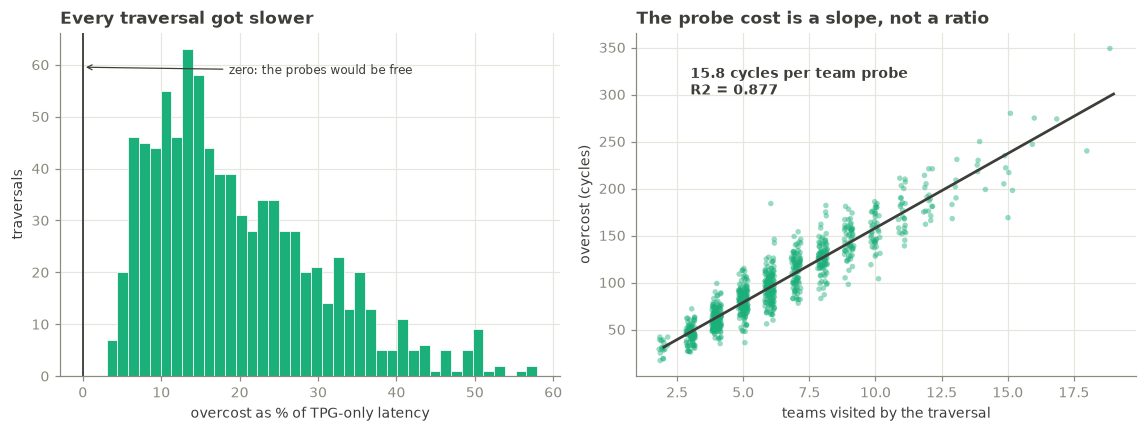

In [86]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.0))
ax1.hist(pct, bins=40, color=C_THIRD, edgecolor="white", linewidth=0.5)
ax1.axvline(0, color=INK, lw=1.2)
ax1.annotate("zero: the probes would be free", xy=(0, ax1.get_ylim()[1]*0.9),
             xytext=(np.percentile(pct, 55), ax1.get_ylim()[1]*0.88), color=INK,
             fontsize=8, arrowprops=dict(arrowstyle="->", color=INK, lw=0.8))
ax1.set(xlabel="overcost as % of TPG-only latency", ylabel="traversals",
        title="Every traversal got slower")

jit = nteams + np.random.default_rng(0).uniform(-0.18, 0.18, len(nteams))
ax2.scatter(jit, overcost, s=13, color=C_THIRD, alpha=0.45, edgecolor="none")
xs = np.array([nteams.min(), nteams.max()])
ax2.plot(xs, f_probe.beta[0]*xs + f_probe.beta[1], color=INK, lw=1.8)
ax2.annotate(f"{f_probe.beta[0]:.1f} cycles per team probe\n"
             f"R2 = {f_probe.r2:.3f}", xy=(nteams.min()+1, overcost.max()*0.86),
             color=INK, fontsize=9, fontweight="semibold")
ax2.set(xlabel="teams visited by the traversal", ylabel="overcost (cycles)",
        title="The probe cost is a slope, not a ratio")
plt.tight_layout(); plt.show()

**Verdict on claim 4: the overcost is real and measured** — every traversal without
exception got slower, by a median 13% of TPG-only latency, and the per-probe cost
comes out of a regression with R2 ~ 0.87 that does not depend on team size.

**But the attribution of the section-3 intercept to it was wrong.** The cell below
compares the measured probe cost against that intercept.

The residual scatter around the regression is larger than the runs' own recorded
stddevs can explain, so something beyond "constant x team count" is going on. The
probe does have one genuinely team-dependent component — it reads `mcycle` with a
`csrr`, and the manual charges +1 or +2 cycles for CSR read/write conflicts
depending on the neighbouring instructions — but that is worth 1-2 cycles, not the
observed spread. Other candidates, which this data cannot separate: the two
instrumentation modes are *separate runs* that may not take identical paths, so the
static team list may be the wrong count for one of them; and probe code displacing
the prefetch buffer would be a whole-traversal effect rather than a per-team one.

In [87]:
probe = f_probe.beta[0]
print(f"measured cost of one team probe   : {probe:6.2f} cycles  (regression slope)")
print(f"fitted per-team constant (sec. 3) : {fit_sl.beta[1]:6.2f} cycles")
print(f"ratio                             : {probe/fit_sl.beta[1]:6.2f}x\n")
print("The two do NOT match, so the intercept cannot simply be 'the probe'.\n")

# How much of the probe lands INSIDE the measured window?  The smallest teams
# answer this with no model at all: a team of k one-cycle instructions cannot
# legitimately report more than k cycles plus whatever the measurement adds.
tiny = [(r.n, estimate(r), r.meas) for r in rows
        if not r.branchy and 3 <= r.n <= 7]
print("Smallest straight-line teams -- the floor of what a measurement can report:")
print(f"  {'instrs':>7}{'teams':>7}{'doc est':>9}{'measured':>10}{'min':>6}{'offset':>9}")
for k in range(3, 8):
    g = [(e, y) for n, e, y in tiny if n == k]
    if not g:
        continue
    est_k = np.mean([e for e, _ in g]); mea_k = np.mean([y for _, y in g])
    print(f"  {k:>7}{len(g):>7}{est_k:>9.1f}{mea_k:>10.1f}"
          f"{min(y for _, y in g):>6.0f}{mea_k-est_k:>9.1f}")
print("\n  A 3-instruction team costing 3 cycles by the manual reports 8, and never")
print("  less than 8. Nothing OUTSIDE a counter-delta window can do that, so ~5")
print("  cycles sit inside it; the rest of the probe lands outside and shows up")
print("  only in the whole-TPG total.")
print("\n  What that 5-7 cycles IS remains open: counter-read asymmetry and probe")
print("  instructions inside the window (an artefact, subtract it), or genuine team")
print("  entry/exit work such as the jump into the team (real, keep it). The two are")
print("  statistically identical here -- both are 'a fixed cost once per team'.")
print("  Settling it needs one run with a deliberately heavier probe: if")
print("  AvgCyclesPerTeam grows by the added nops, the window is porous and the")
print("  constant can be calibrated and subtracted.")

measured cost of one team probe   :  15.83 cycles  (regression slope)
fitted per-team constant (sec. 3) :   8.36 cycles
ratio                             :   1.89x

The two do NOT match, so the intercept cannot simply be 'the probe'.

Smallest straight-line teams -- the floor of what a measurement can report:
   instrs  teams  doc est  measured   min   offset
        3     17      3.0       8.0     8      5.0
        4     15      4.0       9.4     9      5.4
        5     61      5.0      10.6    10      5.6
        6     88      6.0      13.0    10      7.0
        7    173      7.0      14.1     3      7.1

  A 3-instruction team costing 3 cycles by the manual reports 8, and never
  less than 8. Nothing OUTSIDE a counter-delta window can do that, so ~5
  cycles sit inside it; the rest of the probe lands outside and shows up
  only in the whole-TPG total.

  What that 5-7 cycles IS remains open: counter-read asymmetry and probe
  instructions inside the window (an artefact, subtract 

## 6. The scale factor on top of the doc floor

Section 3 fitted a slope above 1. This section shows that gap directly, in cycles,
on straight-line teams only (where the estimate is a valid floor).

In [88]:
e, y = est[SL], meas[SL]
gap = y - e                                   # cycles the manual's table does not explain
ratio = y / np.maximum(e, 1e-9)

print(f"straight-line teams: {SL.sum()}")
print(f"  mean measured        {y.mean():7.2f} cycles")
print(f"  mean doc estimate    {e.mean():7.2f} cycles")
print(f"  mean unexplained gap {gap.mean():7.2f} cycles  ({100*gap.mean()/y.mean():.1f}% of measured)\n")
print(f"  gap    : median {np.median(gap):+.1f}   p10 {np.percentile(gap,10):+.1f}   p90 {np.percentile(gap,90):+.1f} cycles")
print(f"  ratio  : median {np.median(ratio):.2f}x  p10 {np.percentile(ratio,10):.2f}  p90 {np.percentile(ratio,90):.2f}\n")

print("The gap has two parts -- a fixed one and a proportional one. Separate them:")
f_prop = ols(e, y, ["estimate"])
print(f"  measured = {f_prop.beta[0]:.3f} x estimate {f_prop.beta[1]:+.2f}")
print(f"    -> proportional: {100*(f_prop.beta[0]-1):+.1f}% on every cycle the table predicts")
print(f"    -> fixed       : {f_prop.beta[1]:+.2f} cycles per team, independent of size\n")

print("Note the median ratio ({:.2f}x) is far above the slope ({:.3f}) because the"
      .format(np.median(ratio), f_prop.beta[0]))
print("fixed part dominates small teams (median estimate is only {:.0f} cycles)."
      .format(np.median(e)))
print("\nDoes the manual's load-use penalty account for the proportional part?")
f_haz = ols(np.c_[e, lu[SL]], y, ["estimate", "load_use"])
print(f"  {f_haz}")
print(f"  -> estimate coefficient moves {f_prop.beta[0]:.3f} -> {f_haz.beta[0]:.3f}"
      f" (1.000 would mean the doc costs are exactly right once hazards are charged)")

straight-line teams: 2028
  mean measured          30.36 cycles
  mean doc estimate      19.58 cycles
  mean unexplained gap   10.78 cycles  (35.5% of measured)

  gap    : median +10.0   p10 +7.0   p90 +15.0 cycles
  ratio  : median 1.85x  p10 1.32  p90 2.09

The gap has two parts -- a fixed one and a proportional one. Separate them:
  measured = 1.123 x estimate +8.36
    -> proportional: +12.3% on every cycle the table predicts
    -> fixed       : +8.36 cycles per team, independent of size

Note the median ratio (1.85x) is far above the slope (1.123) because the
fixed part dominates small teams (median estimate is only 14 cycles).

Does the manual's load-use penalty account for the proportional part?
  n=2028  estimate=+0.966  load_use=+1.758  const=+5.52   R2=0.9874  MAE=1.31 cyc   [!] collinear, read coefficients with care
  -> estimate coefficient moves 1.123 -> 0.966 (1.000 would mean the doc costs are exactly right once hazards are charged)


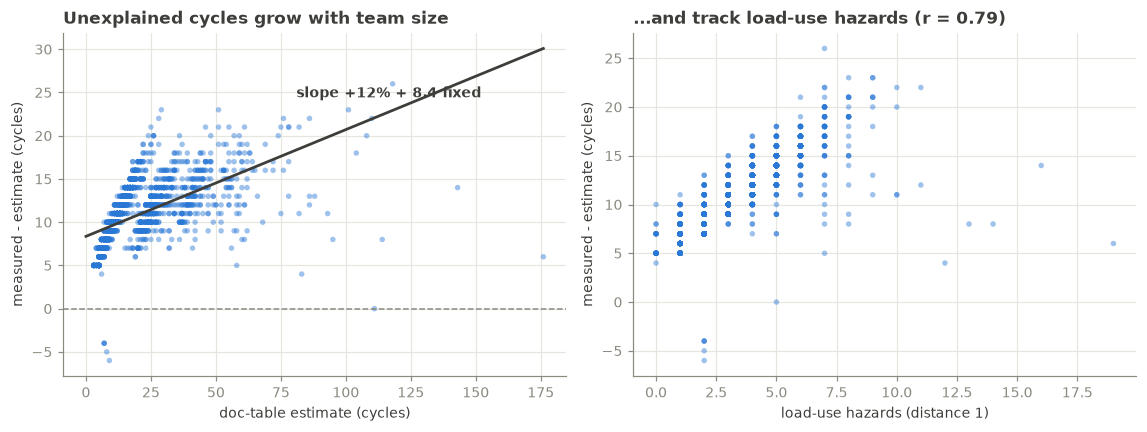

In [89]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.0))
ax1.scatter(e, gap, s=13, color=C_STRAIGHT, alpha=0.45, edgecolor="none")
ax1.axhline(0, color=MUTED, lw=1, ls="--")
xs = np.linspace(0, e.max(), 2)
ax1.plot(xs, (f_prop.beta[0]-1)*xs + f_prop.beta[1], color=INK, lw=1.8)
ax1.annotate(f"slope {100*(f_prop.beta[0]-1):+.0f}% + {f_prop.beta[1]:.1f} fixed",
             xy=(e.max()*0.45, (f_prop.beta[0]-1)*e.max()*0.45 + f_prop.beta[1]),
             xytext=(e.max()*0.46, gap.max()*0.94),
             color=INK, fontsize=9, fontweight="semibold")
ax1.set(xlabel="doc-table estimate (cycles)", ylabel="measured - estimate (cycles)",
        title="Unexplained cycles grow with team size")
ax2.scatter(lu[SL], gap, s=13, color=C_STRAIGHT, alpha=0.45, edgecolor="none")
ax2.set(xlabel="load-use hazards (distance 1)", ylabel="measured - estimate (cycles)",
        title=f"...and track load-use hazards (r = {np.corrcoef(lu[SL], gap)[0,1]:.2f})")
plt.tight_layout(); plt.show()

## 7. What the costs actually are: fitted vs the manual

Instead of testing the table as a whole, let the data solve for each cost. Every
team contributes one equation; the coefficients are per-instruction cycles in the
same units as the manual, so they can be read side by side.

**Caveat, enforced by the printed condition number:** instruction counts and hazard
counts are strongly collinear (a longer team has more of both), so individual
coefficients trade off against each other and should not be read as independent
measurements. The aggregate fit is sound; the per-row attribution is not.

In [90]:
def group_counts(r):
    c = {k: 0 for k in ("alu", "load", "store", "mul", "mulh")}
    for op, n in r.ops.items():
        m = op.lower().split("_")[0]
        if   m in LOADS:  c["load"]  += n
        elif m in STORES: c["store"] += n
        elif m in MULH:   c["mulh"]  += n
        elif m == "mul":  c["mul"]   += n
        else:             c["alu"]   += n
    return c

G = [group_counts(r) for r, s in zip(rows, SL) if s]
X = np.array([[g["alu"], g["load"], g["store"], g["mul"], g["mulh"]] for g in G], float)
X = np.c_[X, lu[SL], np.array([r.alu_haz for r, s in zip(rows, SL) if s], float)]
names = ["ALU", "load", "store", "mul", "mulh*", "load-use haz", "alu-alu haz"]
doc   = [1, 1, 1, 1, 4, 1, 0]

f = ols(X, y, names)
print(f"{SL.sum()} straight-line teams   R2 = {f.r2:.4f}   MAE = {f.mae:.2f} cycles"
      f"   cond = {f.cond:.0f}\n")
print(f"  {'feature':<16}{'fitted':>9}{'doc':>7}{'mean/team':>12}")
print("  " + "-" * 44)
for nm, b, d, col in zip(names, f.beta[:-1], doc, X.T):
    print(f"  {nm:<16}{b:>9.3f}{d:>7}{col.mean():>12.1f}")
print(f"  {'constant':<16}{f.beta[-1]:>9.3f}{'--':>7}")
print("\n  'mul' lands on the doc value; the negative alu-alu hazard coefficient is")
print("  physically meaningless and is the collinearity showing -- it absorbs part of")
print("  the ALU/load/store inflation. Treat the table as a whole, not row by row.")

2028 straight-line teams   R2 = 0.9934   MAE = 0.90 cycles   cond = 253

  feature            fitted    doc   mean/team
  --------------------------------------------
  ALU                 1.204      1         7.0
  load                1.646      1         5.1
  store               1.794      1         3.5
  mul                 0.734      1         1.7
  mulh*               7.469      4         0.6
  load-use haz        0.287      1         3.4
  alu-alu haz        -0.875      0         2.7
  constant            3.157     --

  'mul' lands on the doc value; the negative alu-alu hazard coefficient is
  physically meaningless and is the collinearity showing -- it absorbs part of
  the ALU/load/store inflation. Treat the table as a whole, not row by row.


## 8. Knobs to iterate on

The three doc rows that depend on run-time state, swept against the data. Remember
section 4: `div` and `branch` only affect branchy teams, where the floor is already
violated, so their "best" values here are fitting artefacts, not calibrations. The
`mulh` sweep is the only one on clean ground — and it shows `mulh` is poorly
identified, since it appears under one time per team.

In [91]:
def sweep(key_costs, mask, label):
    c = dict(COSTS); c.update(key_costs)
    e_ = np.array([estimate(r, c) for r in rows], float)[mask]
    y_ = meas[mask]
    f_ = ols(e_, y_, ["est"])
    print(f"  {label:<26} slope={f_.beta[0]:.3f}  R2={f_.r2:.4f}  "
          f"MAE={f_.mae:5.2f}  floor violated {100*(e_>y_).mean():5.1f}%")

print("DIV_CYCLES (branchy teams only -- doc range is 3-35):")
for d in (3, 10, 20, 35):
    sweep({k: d for k in ("div","divu","rem","remu")}, ~SL, f"div={d}")
print("\nBRANCH_CYCLES (branchy teams only -- doc: 1 not-taken, 3 taken):")
for b in (1, 2, 3):
    sweep({k: b for k in ("beq","bne","blt","bge","bltu","bgeu","beqz","bnez",
                          "blez","bgez","bltz","bgtz")}, ~SL, f"branch={b}")
print("\nmulh (straight-line teams -- doc: 4):")
for k in (1, 2, 3, 4, 5, 6):
    sweep({m: k for m in MULH}, SL, f"mulh={k}")
print(f"\n  mulh* occurrences per straight-line team: mean "
      f"{np.array([g['mulh'] for g in G]).mean():.2f} -- too few to pin the value down.")

DIV_CYCLES (branchy teams only -- doc range is 3-35):
  div=3                      slope=0.678  R2=0.5585  MAE=60.80  floor violated  37.0%
  div=10                     slope=0.650  R2=0.5551  MAE=60.37  floor violated  37.9%
  div=20                     slope=0.611  R2=0.5495  MAE=59.90  floor violated  38.8%
  div=35                     slope=0.559  R2=0.5403  MAE=59.56  floor violated  51.9%

BRANCH_CYCLES (branchy teams only -- doc: 1 not-taken, 3 taken):
  branch=1                   slope=0.559  R2=0.5403  MAE=59.56  floor violated  51.9%
  branch=2                   slope=0.543  R2=0.5366  MAE=59.92  floor violated  54.9%
  branch=3                   slope=0.529  R2=0.5330  MAE=60.27  floor violated  57.7%

mulh (straight-line teams -- doc: 4):
  mulh=1                     slope=1.367  R2=0.9875  MAE= 1.36  floor violated   0.2%
  mulh=2                     slope=1.276  R2=0.9846  MAE= 1.59  floor violated   0.2%
  mulh=3                     slope=1.196  R2=0.9812  MAE= 1.83  flo

## Summary

| Claim | Status | Number |
|---|---|---|
| Model works on straight-line code | **holds** | R2 = 0.977, MAE ~ 2 cycles, floor violated 0.2% |
| Model works on branchy code | **fails** | R2 = 0.44, floor violated 68.5% |
| The branchy failure is skipped code | **holds, and it dominates** | pricing `div` at 1 cycle still leaves 49% violating; implied cycles/div is negative for 52% of teams |
| ...but `div`=35 amplifies it | **holds** | 69% -> 49% violations when `div` drops from 35 to 1 (~20 points) |
| `div` can be calibrated from this data | **no** | 100% of divs are in branchy teams, where the floor is already broken |
| Uncounted callee bodies distort this data | **no** | only 19 call instructions in the whole database |
| An instrumentation overcost exists | **measured** | +13% median, 0% negative; 15.4 cycles per probe by regression (R2 0.87) |
| The section-3 intercept is that probe | **partly** | ~5 of the 15.4 is inside the measured window (3-instruction teams report 8); the split between artefact and real team entry cost is unresolved |
| A systematic scale factor sits on the doc floor | **holds** | +11% proportional, falling to +2% once the manual's load-use penalty is charged |

**Where to go next**, in order of value:

1. **Dynamic instruction counts.** Per-basic-block instrumentation, or execution
   counts from the simulator, would fix the branchy half — which is where the divs,
   and most of the interesting latency, live. Nothing else on this list matters as
   much.
2. **Calibrate the per-team constant.** One run with N nops added inside the probe
   splits measurement artefact from genuine team entry cost. Until then the constant
   is absorbed by an intercept, which is fine for per-team prediction but
   over-counts by ~7 x n_teams when summing a traversal.
3. **Exercise the cost table.** This workload is ~95% one-cycle instructions, so the
   per-instruction costs are barely tested. A workload with more `mulh`/`div`/loads
   would show whether the table earns its keep over simply counting instructions.